# Practical No-05: Image Generation using Pretrained Stable Diffusion

**Name:** Manmath Maroti Kornule  |  **PRN:** 202401110045  |  **Batch:** A3  
**Runtime:** Google Colab with **GPU** (Runtime > Change runtime type > T4 GPU)

## Aim
To generate images from text prompts using a pretrained Stable Diffusion model (Hugging Face Diffusers), and to study how **inference steps**, **guidance scale** and **sampling methods** change the quality of the generated images.


Stable Diffusion draws a picture starting from pure random noise (like TV static). Step by step, it removes a little noise each time, and the text prompt tells it what the picture should look like. We do not train anything here; we use a model that is already trained and only change three settings:

| Setting | Simple meaning |
|---|---|
| Inference steps | How many times the model cleans the noise. More steps = more refining, but slower |
| Guidance scale | How strictly the model must follow the prompt. Low = free and creative, high = strict |
| Sampling method (scheduler) | The method used to remove noise in each step. Different methods reach a good image at different speeds |

## Flow of this notebook
1. Setup and GPU check
2. Load the pretrained model
3. Generate the first image
4. Generate images for different prompts
5. Effect of inference steps
6. Effect of guidance scale
7. Effect of sampling methods
8. Measuring quality with numbers (CLIP score)
9. Summary and conclusion

---

colab link : https://colab.research.google.com/drive/1_AmQSpOcRJlcL15CnW98yEsoyIdmyOni?usp=sharing

## 1. Setup

In [1]:
%pip -q install diffusers transformers accelerate safetensors

In [2]:
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: No GPU found. Please switch to a GPU runtime, otherwise generation will be extremely slow.")
else:
    print("GPU name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU name: Tesla T4


## 2. Load the pretrained model

We use **Stable Diffusion v1.5** from Hugging Face. On a GPU we load it in half precision (`float16`) to save memory and time.  
The first run downloads the model (about 4 GB), so it can take a few minutes.

In [3]:
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=dtype)
pipe = pipe.to(device)

# keep the original (default) sampler settings so we can reset to them later
default_scheduler_config = pipe.scheduler.config
print("Model loaded. Default sampler:", pipe.scheduler.__class__.__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Model loaded. Default sampler: PNDMScheduler


## 3. Helper functions

- `generate_image` creates one image and also measures how long it took.
- `show_images` displays several images side by side with titles.

We always use a fixed **seed**. With the same seed the starting noise is identical, so any change in the image is caused only by the setting we changed.

In [4]:
def generate_image(prompt, steps=30, guidance=7.5, seed=42):
    generator = torch.Generator(device=device).manual_seed(seed)

    if device == "cuda":
        torch.cuda.synchronize()
    start = time.time()

    image = pipe(
        prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator
    ).images[0]

    if device == "cuda":
        torch.cuda.synchronize()
    seconds = time.time() - start
    return image, seconds


def show_images(images, titles, cols=None, size=3.6):
    n = len(images)
    cols = cols or n
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows + 0.4))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## 4. First image from a text prompt

We write a prompt in plain English and let the model draw it. This prompt is also used for the experiments later.

  0%|          | 0/30 [00:00<?, ?it/s]

Time taken: 7.1 seconds


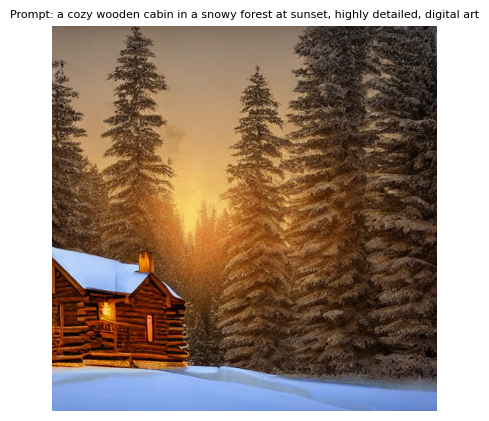

In [5]:
main_prompt = "a cozy wooden cabin in a snowy forest at sunset, highly detailed, digital art"

image, seconds = generate_image(main_prompt, steps=30, guidance=7.5, seed=42)
print(f"Time taken: {seconds:.1f} seconds")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Prompt: " + main_prompt, fontsize=8)
plt.show()

## 5. Different prompts

The same model can draw very different things just by changing the text. Here we use four prompts with the same settings (30 steps, guidance 7.5).

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

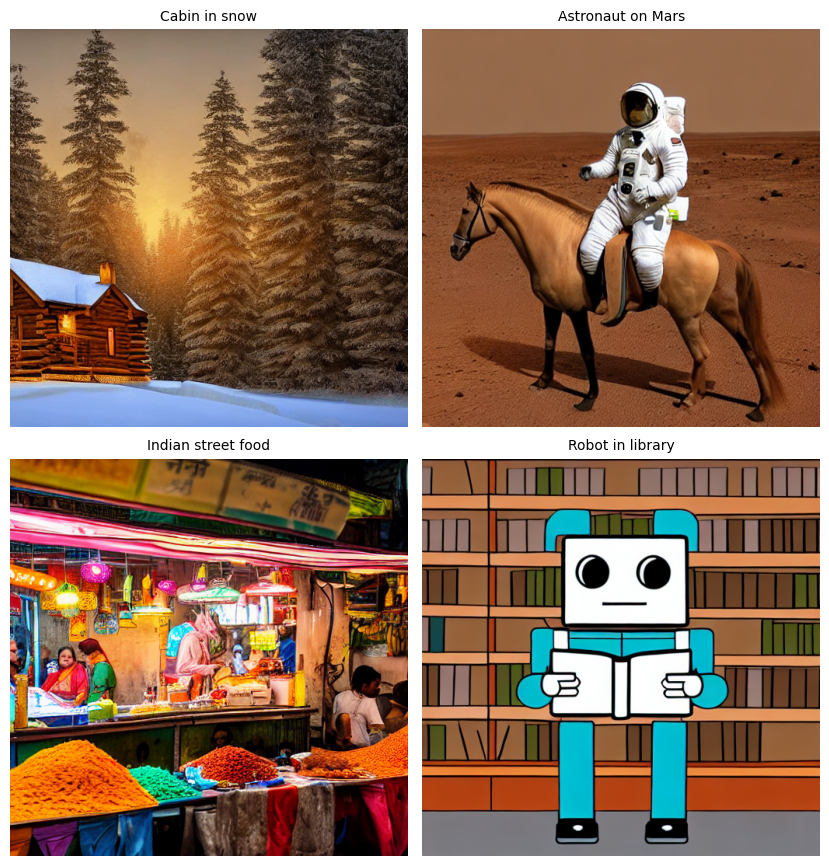

In [6]:
prompts = [
    "a cozy wooden cabin in a snowy forest at sunset, highly detailed, digital art",
    "an astronaut riding a horse on mars, realistic photo",
    "a colorful street food stall in an Indian market, cinematic lighting",
    "a cute robot reading a book in a library, cartoon style",
]

prompt_images = []
for p in prompts:
    img, sec = generate_image(p, steps=30, guidance=7.5, seed=42)
    prompt_images.append(img)

short_titles = ["Cabin in snow", "Astronaut on Mars", "Indian street food", "Robot in library"]
show_images(prompt_images, short_titles, cols=2, size=4.2)

## 6. Effect of inference steps

We keep the prompt, guidance (7.5) and seed fixed, and change only the number of steps. We also note the time taken, because more steps cost more time.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

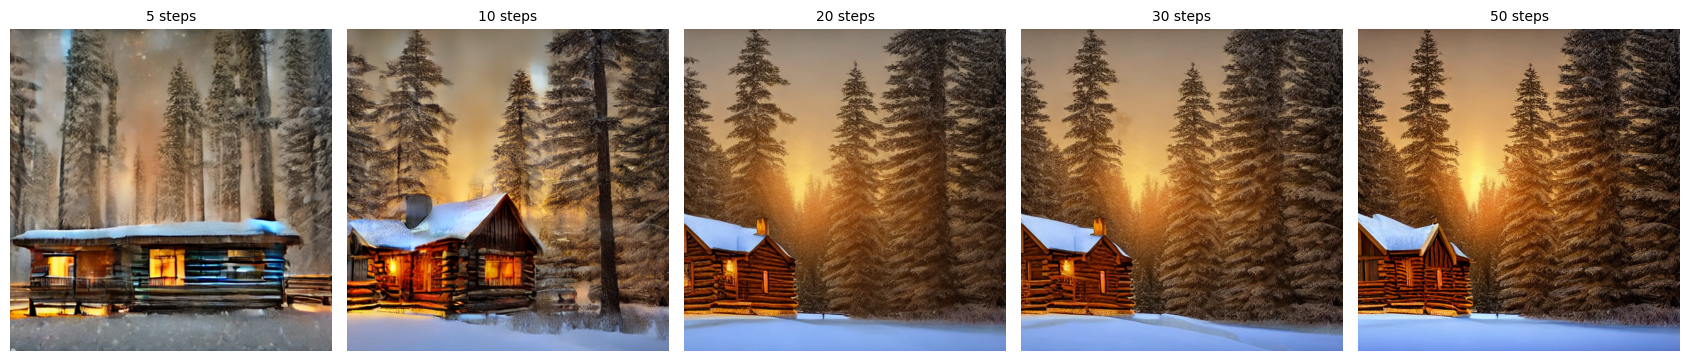

In [7]:
step_values = [5, 10, 20, 30, 50]

step_images, step_times = [], []
for s in step_values:
    img, sec = generate_image(main_prompt, steps=s, guidance=7.5, seed=42)
    step_images.append(img)
    step_times.append(sec)

show_images(step_images, [f"{s} steps" for s in step_values], cols=5, size=3.4)

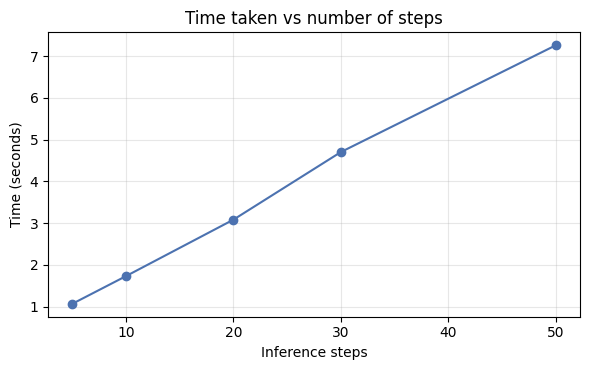

In [8]:
plt.figure(figsize=(6, 3.8))
plt.plot(step_values, step_times, marker="o", color="#4C72B0")
plt.title("Time taken vs number of steps")
plt.xlabel("Inference steps")
plt.ylabel("Time (seconds)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Effect of guidance scale

Now we keep steps (30) and seed fixed and change only the guidance scale.  
A very low value mostly ignores the prompt; a very high value follows it too strictly and the colours can look harsh or unnatural.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

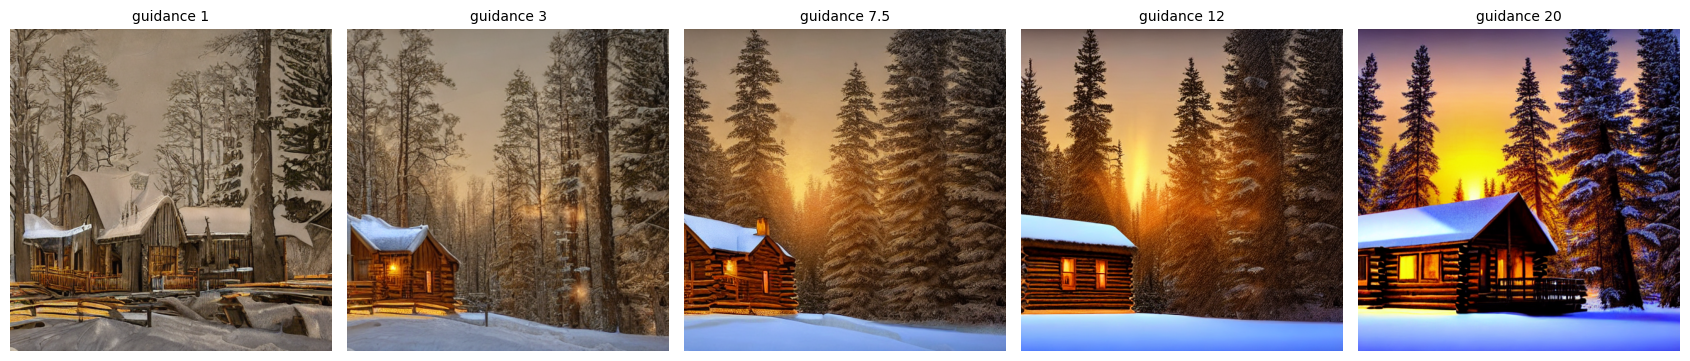

In [9]:
guidance_values = [1, 3, 7.5, 12, 20]

guidance_images, guidance_times = [], []
for g in guidance_values:
    img, sec = generate_image(main_prompt, steps=30, guidance=g, seed=42)
    guidance_images.append(img)
    guidance_times.append(sec)

show_images(guidance_images, [f"guidance {g}" for g in guidance_values], cols=5, size=3.4)

## 8. Effect of sampling methods

A scheduler (sampler) decides *how* the noise is removed at every step. We compare five popular ones with the same prompt, seed, steps (25) and guidance (7.5).

| Sampler | Short note |
|---|---|
| PNDM | Default sampler of Stable Diffusion v1.5 |
| DDIM | Simple and fast, gives stable results |
| Euler | Popular fast sampler |
| Euler Ancestral | Adds a little fresh randomness at each step, so images can look different |
| DPM++ | Newer sampler, known to give good images in fewer steps |

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

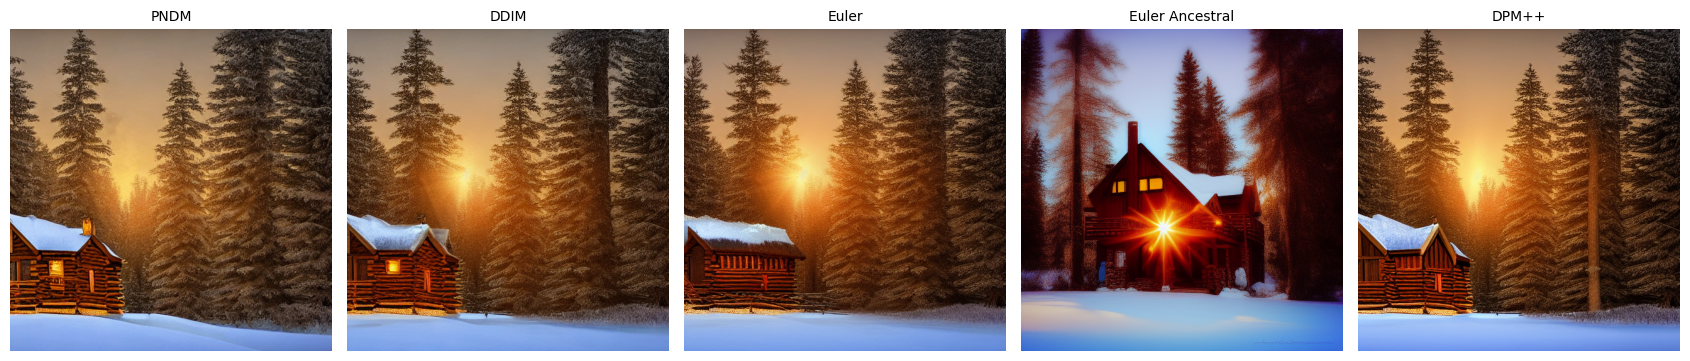

In [10]:
from diffusers import (
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
)

samplers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM++": DPMSolverMultistepScheduler,
}

def use_sampler(name):
    pipe.scheduler = samplers[name].from_config(default_scheduler_config)

sampler_images, sampler_times = [], []
for name in samplers:
    use_sampler(name)
    img, sec = generate_image(main_prompt, steps=25, guidance=7.5, seed=42)
    sampler_images.append(img)
    sampler_times.append(sec)

show_images(sampler_images, list(samplers.keys()), cols=5, size=3.4)

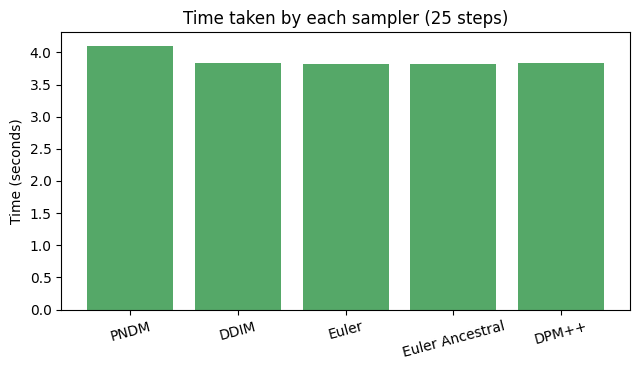

In [11]:
plt.figure(figsize=(6.5, 3.8))
plt.bar(list(samplers.keys()), sampler_times, color="#55A868")
plt.title("Time taken by each sampler (25 steps)")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Samplers with very few steps

A good sampler should give a decent picture even with a small number of steps. We try all five samplers with only **8 steps**.

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

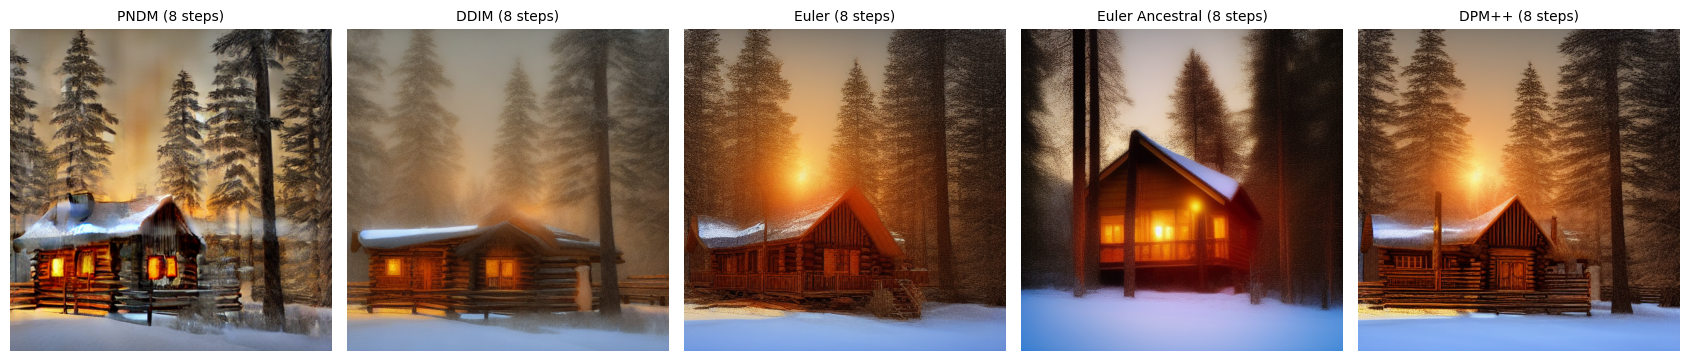

In [12]:
low_step_images = []
for name in samplers:
    use_sampler(name)
    img, sec = generate_image(main_prompt, steps=8, guidance=7.5, seed=42)
    low_step_images.append(img)

show_images(low_step_images, [f"{n} (8 steps)" for n in samplers], cols=5, size=3.4)

# go back to the default sampler
pipe.scheduler = PNDMScheduler.from_config(default_scheduler_config)

## 9. Measuring quality with numbers (CLIP score)

Looking at images is subjective, so we also use a number. **CLIP** is a model that understands both images and text. It gives a score for how well an image matches a sentence: a **higher score means the image matches the prompt better**.

This score only measures *match with the prompt*, not beauty or sharpness, so we use it together with our own eyes.

In [13]:
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def clip_score(image, prompt):
    inputs = clip_processor(text=[prompt], images=image, return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.no_grad():
        outputs = clip_model(**inputs)
    return outputs.logits_per_image.item()

step_scores = [clip_score(img, main_prompt) for img in step_images]
guidance_scores = [clip_score(img, main_prompt) for img in guidance_images]
sampler_scores = [clip_score(img, main_prompt) for img in sampler_images]
print("CLIP scores calculated")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP scores calculated


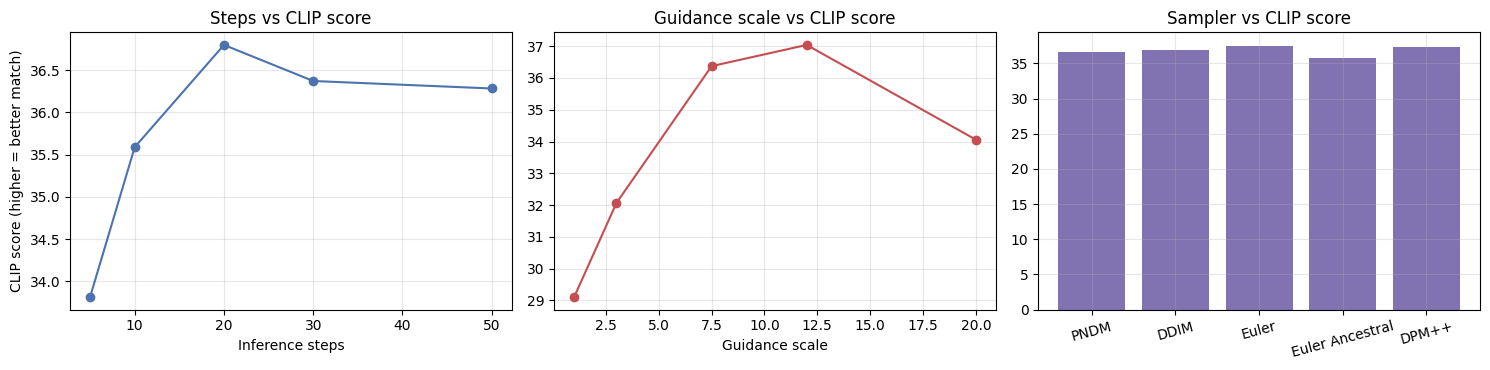

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].plot(step_values, step_scores, marker="o", color="#4C72B0")
axes[0].set_title("Steps vs CLIP score")
axes[0].set_xlabel("Inference steps")
axes[0].set_ylabel("CLIP score (higher = better match)")

axes[1].plot(guidance_values, guidance_scores, marker="o", color="#C44E52")
axes[1].set_title("Guidance scale vs CLIP score")
axes[1].set_xlabel("Guidance scale")

axes[2].bar(list(samplers.keys()), sampler_scores, color="#8172B2")
axes[2].set_title("Sampler vs CLIP score")
axes[2].tick_params(axis="x", rotation=15)

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Summary table

In [15]:
steps_table = pd.DataFrame({"Steps": step_values, "Time (s)": np.round(step_times, 1), "CLIP score": np.round(step_scores, 2)})
guidance_table = pd.DataFrame({"Guidance": guidance_values, "CLIP score": np.round(guidance_scores, 2)})
sampler_table = pd.DataFrame({"Sampler": list(samplers.keys()), "Time (s)": np.round(sampler_times, 1), "CLIP score": np.round(sampler_scores, 2)})

print("Inference steps")
display(steps_table)
print("Guidance scale")
display(guidance_table)
print("Sampling methods")
display(sampler_table)

Inference steps


,Steps,Time (s),CLIP score
0,5,1.1,33.82
1,10,1.7,35.59
2,20,3.1,36.80
3,30,4.7,36.37
4,50,7.3,36.28


Guidance scale


,Guidance,CLIP score
0,1.0,29.11
1,3.0,32.07
2,7.5,36.37
3,12.0,37.04
4,20.0,34.06


Sampling methods


,Sampler,Time (s),CLIP score
0,PNDM,4.1,36.68
1,DDIM,3.8,36.85
2,Euler,3.8,37.55
3,Euler Ancestral,3.8,35.82
4,DPM++,3.8,37.28


In [16]:
# Quick summary generated from our own results
best_steps = step_values[int(np.argmax(step_scores))]
best_guidance = guidance_values[int(np.argmax(guidance_scores))]
best_sampler = list(samplers.keys())[int(np.argmax(sampler_scores))]
fastest_sampler = list(samplers.keys())[int(np.argmin(sampler_times))]

print("Best number of steps (highest CLIP score):", best_steps)
print("Best guidance scale (highest CLIP score):", best_guidance)
print("Best sampler (highest CLIP score):", best_sampler)
print("Fastest sampler:", fastest_sampler)

Best number of steps (highest CLIP score): 20
Best guidance scale (highest CLIP score): 12
Best sampler (highest CLIP score): Euler
Fastest sampler: Euler Ancestral


## 11. Observations

Based on our execution results and generated charts, here are the completed observations:

1. **Inference steps:** With very few steps (5), the image was blurry and unfinished (CLIP score: 33.82). As steps increased, the image quality and matching score improved significantly, peaking at **20 steps** with a CLIP score of **36.80** in just **3.1 seconds**. Beyond 20 steps (30 and 50 steps), the CLIP score slightly decreased (36.37 and 36.28) while the inference time continued to grow linearly up to **7.3 seconds**.
   *My observation:* 20 steps represents the optimal balance of speed and image alignment for this model.

2. **Guidance scale:** At guidance 1.0, the image is loosely related to the prompt (CLIP score: 29.11). The best alignment is observed at **guidance 12.0** with a peak CLIP score of **37.04**, closely followed by guidance 7.5 (36.37). At a very high guidance of 20.0, the CLIP score dropped back down to 34.06 and the styling became unnatural.
   *My observation:* A sweet spot exists between 7.5 and 12.0 where the model strictly follows instructions without introducing visual artifacts.

3. **Sampling methods:** At 25 steps, all tested samplers took roughly the same time (~3.8s to 4.1s). The **Euler** sampler achieved the highest prompt alignment with a CLIP score of **37.55**, followed by **DPM++** (37.28). When limited to a very small budget of **8 steps**, DPM++ and Euler-based samplers delivered recognizable structures, proving far superior to the default PNDM scheduler at ultra-low step counts.
   *My observation:* Euler and DPM++ are highly efficient samplers, making them ideal when fast generation or lower step limits are needed.

4. **CLIP score:** The CLIP scores correctly tracked the major qualitative changes—such as the massive improvement going from 5 to 20 steps, or the drop-off at bad guidance scales (1.0 and 20.0).
   *My observation:* CLIP scores are excellent for identifying outright failures or optimal parameters, but fine differences between high-scoring images (e.g., Euler vs DPM++) are best judged visually.

## 12. Conclusion

- A pretrained Stable Diffusion model can generate good images from simple text prompts without any training, using only a few lines of the Diffusers library.
- **Inference steps** control the level of detail; there is a point after which extra steps only cost time.
- **Guidance scale** controls how strictly the prompt is followed; a medium value (about 7 to 12) gives the best balance between following the prompt and keeping the image natural.
- **Sampling methods** decide how quickly a good image is reached; modern samplers such as DPM++ can give good quality in fewer steps, which saves time.
- A good practical setting for most prompts is around **20 to 30 steps, guidance of about 7.5 and a fast sampler such as DPM++**.

---
**End of notebook.**